In [2]:
from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces, get_variance_explained

import os
import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA

In [3]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

## fit reconstructed pca traces to cca

0.4292442144172488


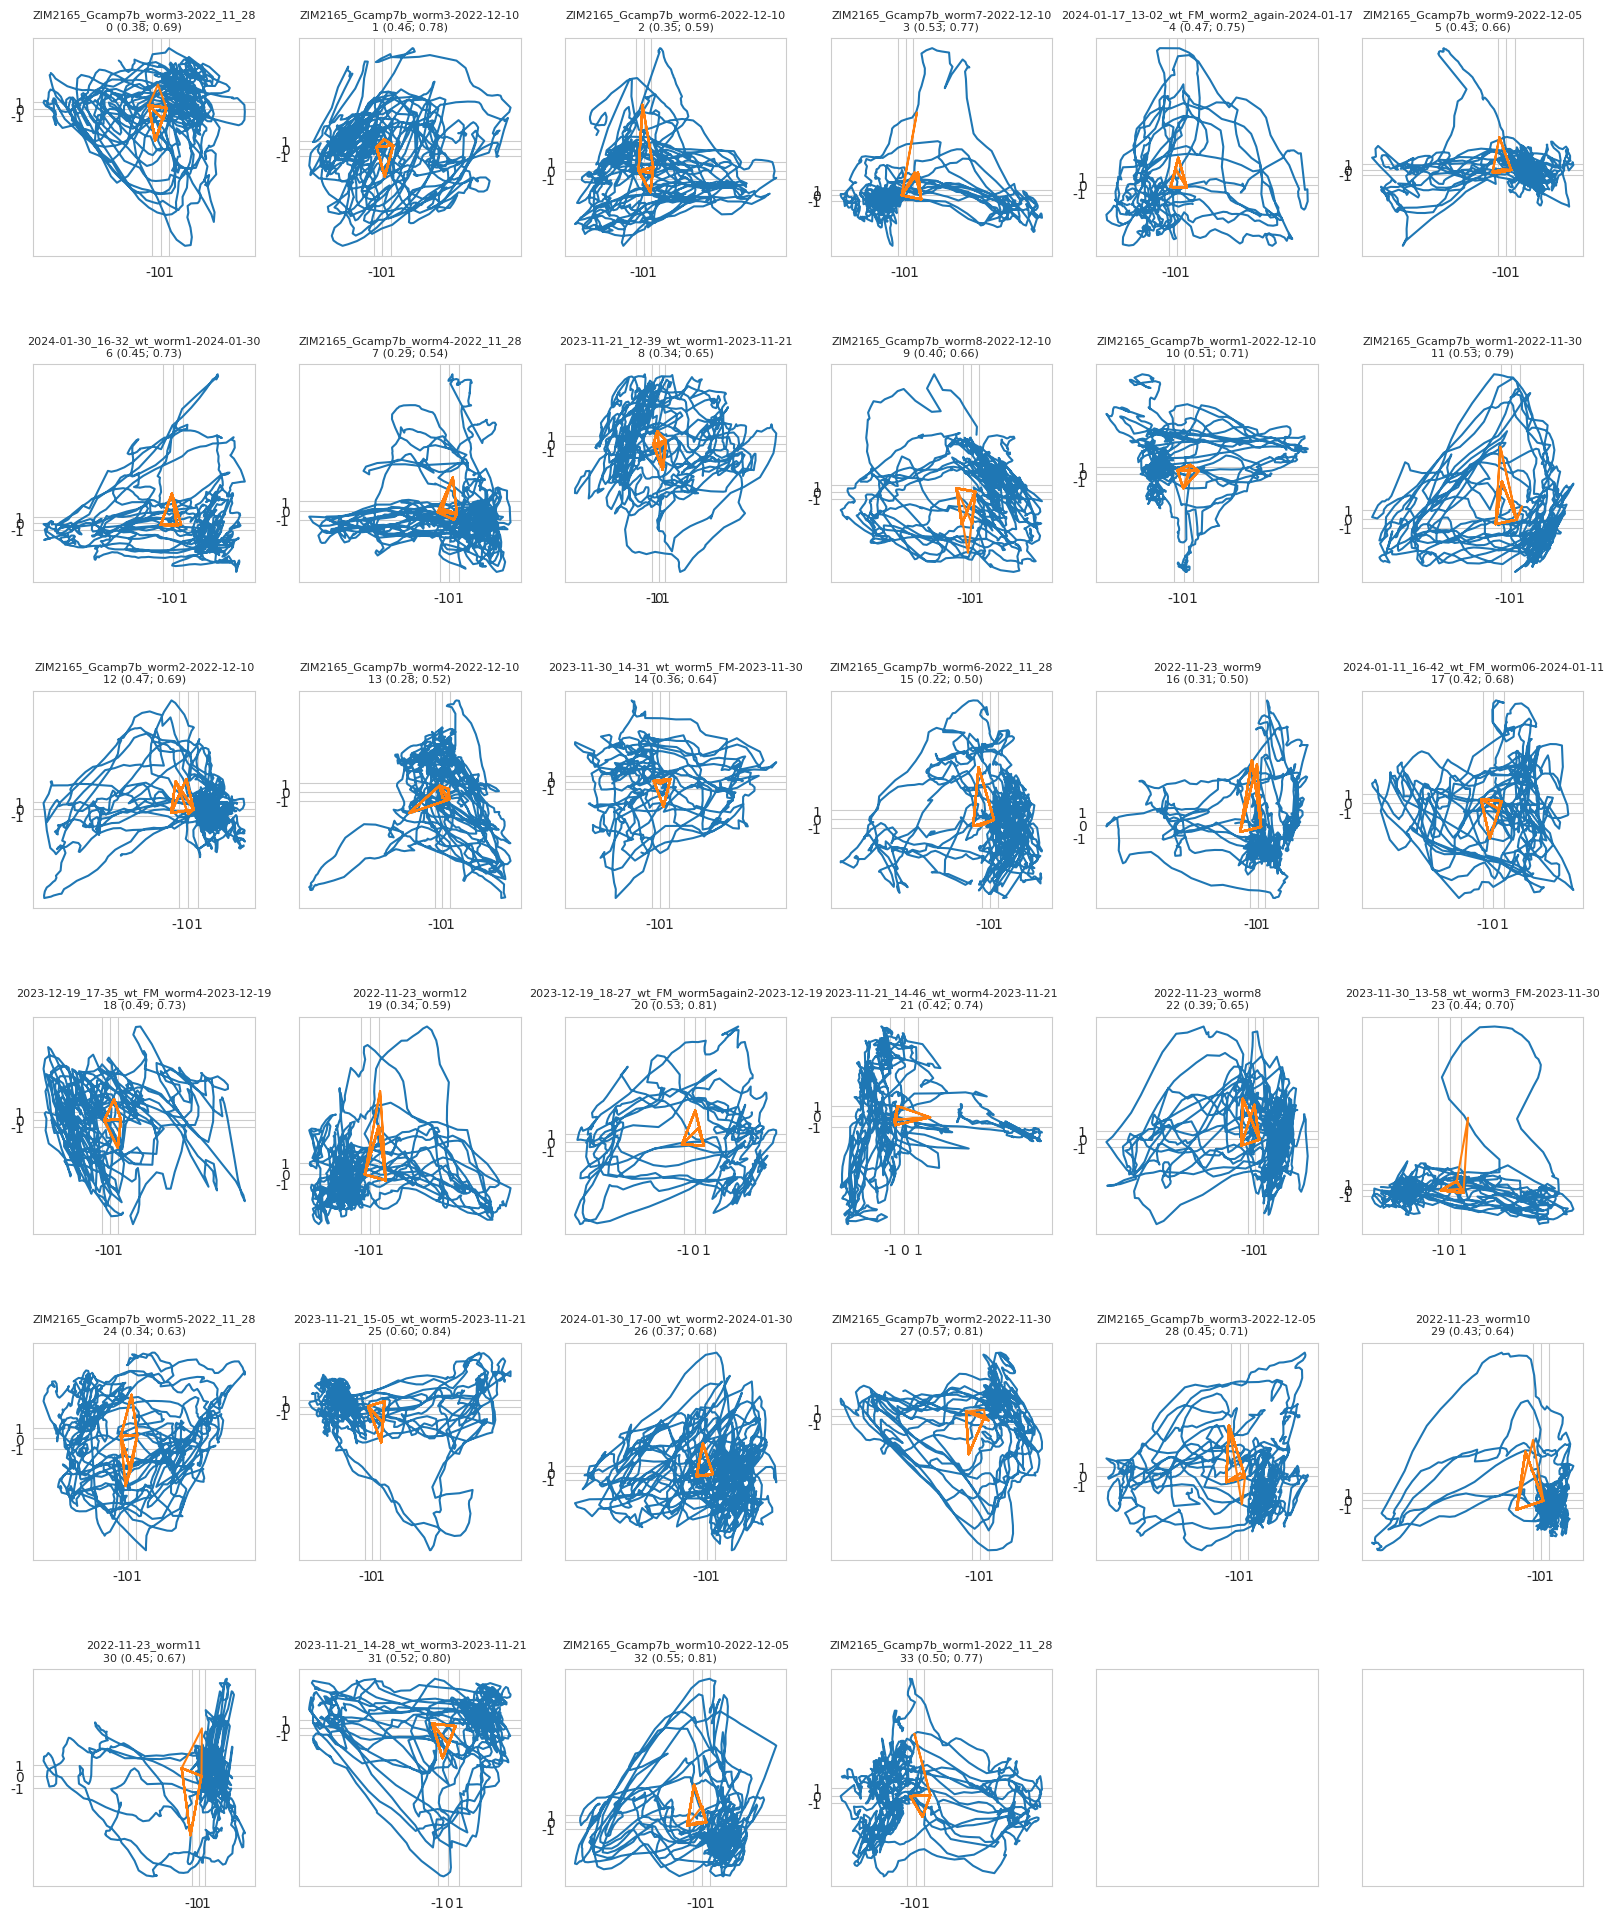

In [4]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

traces_x_ds_reduced_cca = list()
vars_explained_pcarec = list()  # variance explained with respect to the reconstructed PCA data
vars_explained = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=5)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)

	cca = CCA(n_components=2, scale=True)
	trace_reduced_cca, ds_reduced_cca = cca.fit_transform(trace_reconstructed, ds[selection].values)
	trace_reconstructed_cca, ds_reconstructed_cca = cca.inverse_transform(trace_reduced_cca, ds_reduced_cca)
	traces_x_ds_reduced_cca.append((trace_reduced_cca, ds_reduced_cca))

	X_var_ratio_pcarec = get_variance_explained(trace_reconstructed, trace_reconstructed_cca)
	X_var_ratio = get_variance_explained(trace, trace_reconstructed_cca)
	vars_explained_pcarec.append(X_var_ratio_pcarec)
	vars_explained.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, (X_c, Y_c) in enumerate(traces_x_ds_reduced_cca):
	axes[i // dim, i % dim].plot(X_c[:, 0], X_c[:, 1])
	axes[i // dim, i % dim].plot(Y_c[:, 0], Y_c[:, 1])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({vars_explained[i]:.2f}; {vars_explained_pcarec[i]:.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(vars_explained)))

## fit raw traces to cca

0.29840919771893853


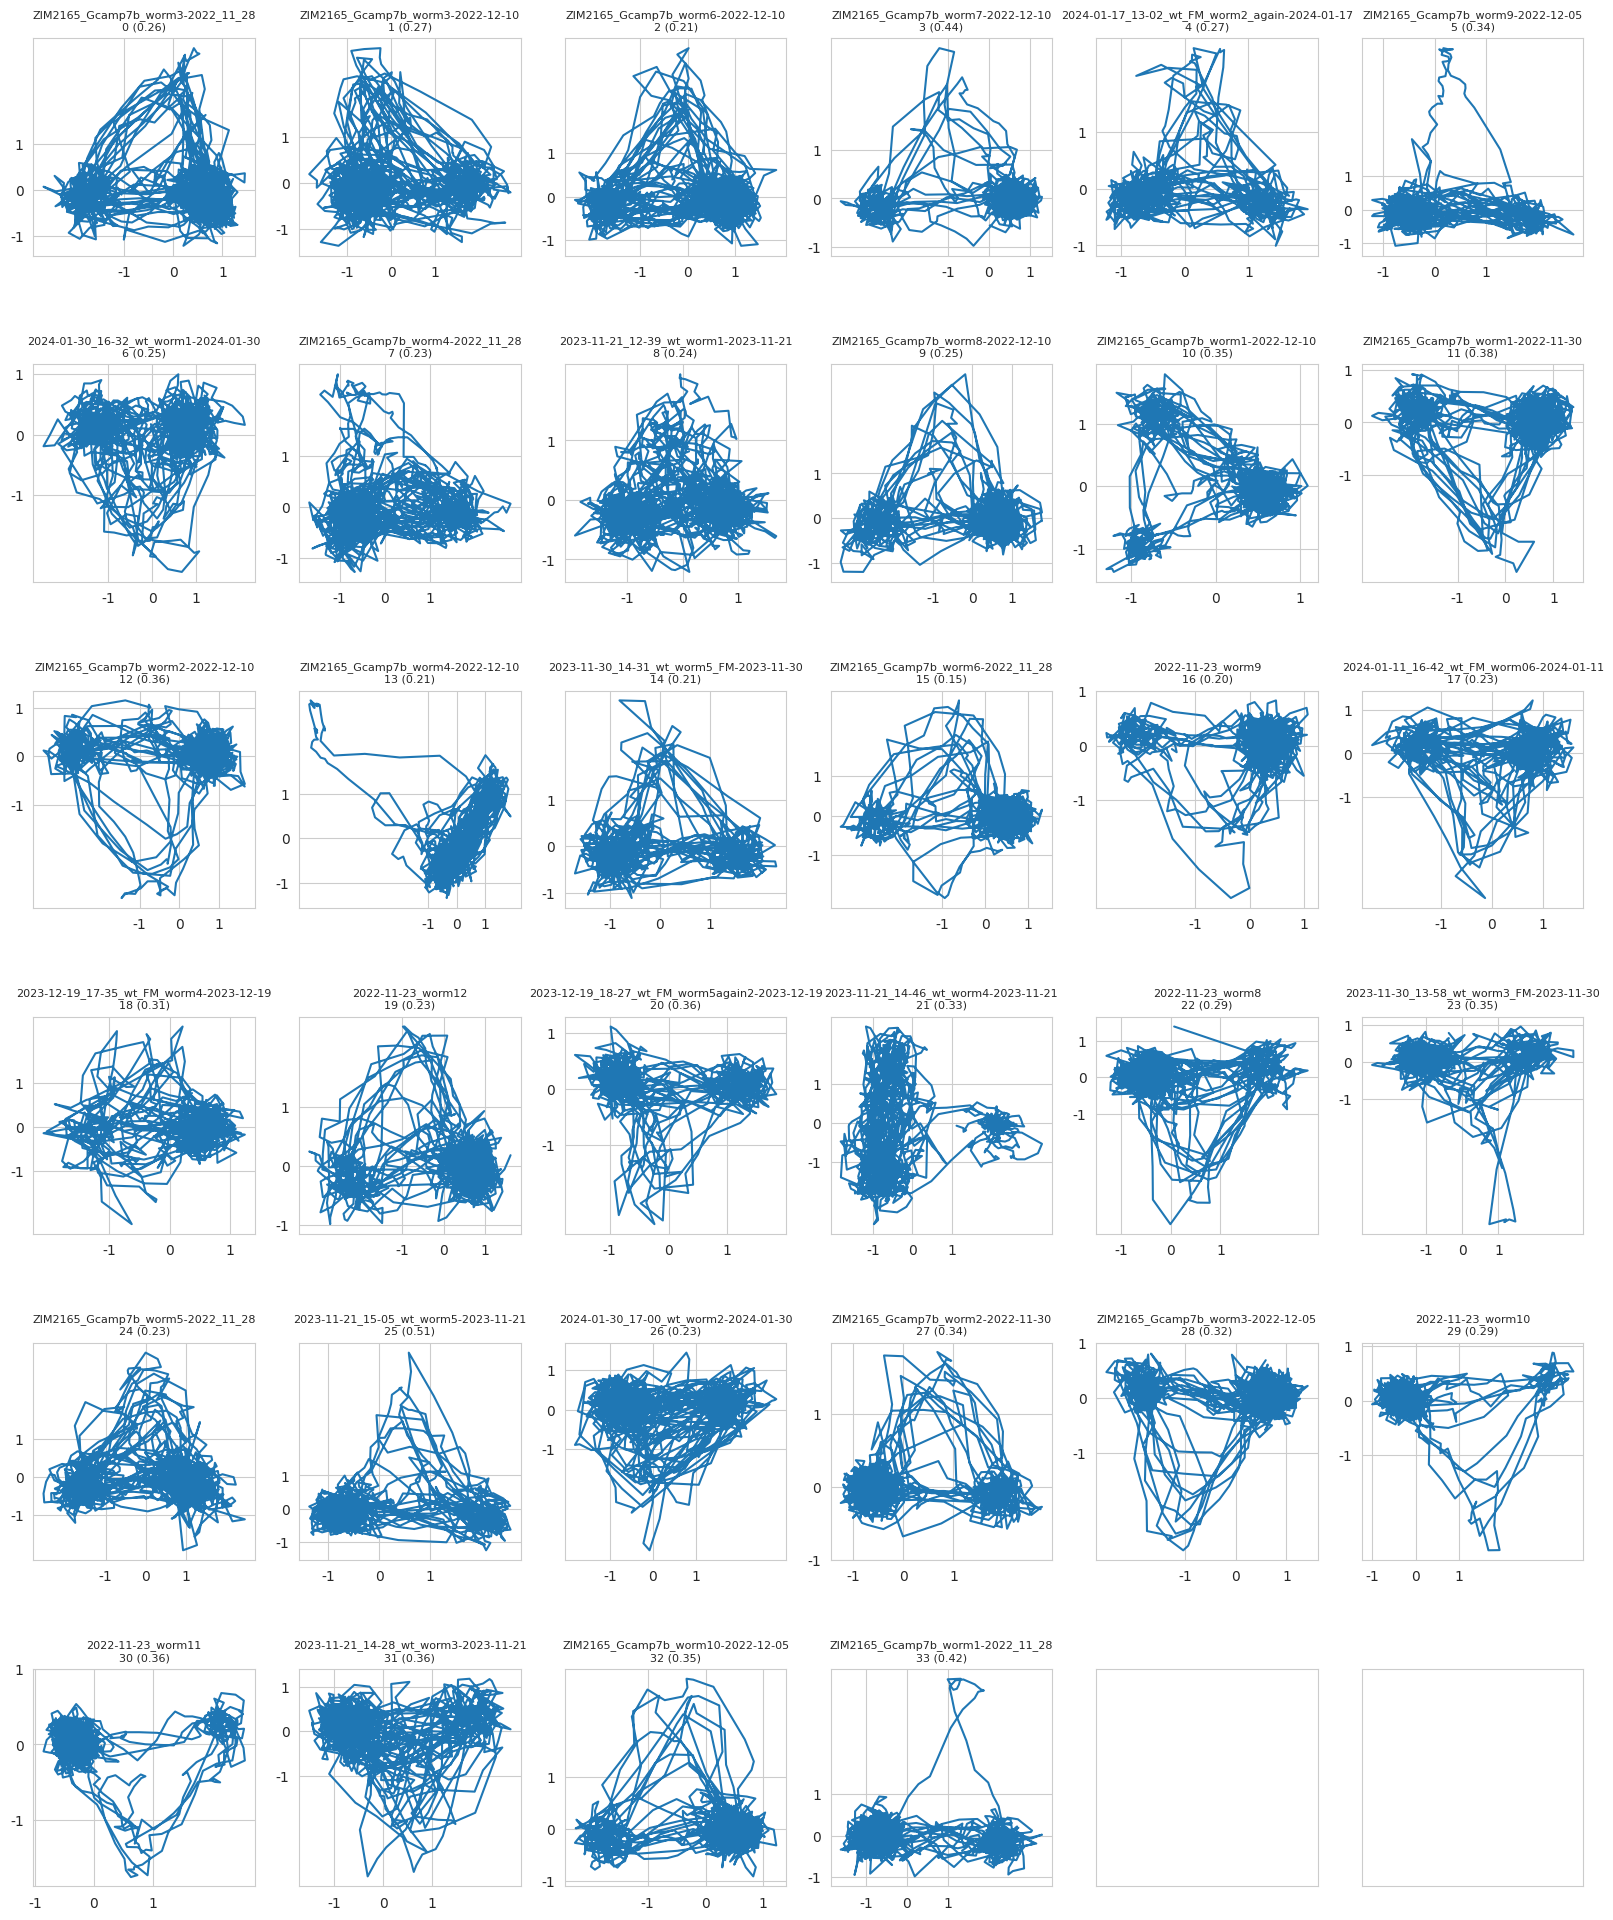

In [5]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

traces_x_ds_reduced_cca = list()
vars_explained = list()
for trace, ds in zip(traces, discrete_states):

	cca = CCA(n_components=len(selection), scale=True)
	trace_reduced_cca, ds_reduced_cca = cca.fit_transform(trace, ds[selection].values)
	trace_reconstructed_cca, ds_reconstructed_cca = cca.inverse_transform(trace_reduced_cca, ds_reduced_cca)
	traces_x_ds_reduced_cca.append((trace_reduced_cca, ds_reduced_cca))

	X_var_ratio = get_variance_explained(trace, trace_reconstructed_cca)
	vars_explained.append(X_var_ratio)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, (X_c, Y_c) in enumerate(traces_x_ds_reduced_cca):
	axes[i // dim, i % dim].plot(X_c[:, 0], X_c[:, 1])
	#axes[i // dim, i % dim].plot(Y_c[:, 0], Y_c[:, 1])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({vars_explained[i]:.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.mean(np.array(vars_explained)))